# Model Selection and Hyperparameter Tuning

**Use scikit-learn as much as possible!**

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor

In [15]:
df_ames = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/main/data/AmesHousing.txt", sep="\t")
df_ames
y = df_ames["SalePrice"]

folds = KFold(n_splits=5, shuffle=True, random_state=5544)     # the same 5 folds for every candidate

def preprocessing(numeric, categorical=(), scale=True):
    """Impute + (optionally) scale the numeric columns; one-hot encode the categorical ones."""
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scale",StandardScaler()))
    transformers = [("num", Pipeline(numeric_steps), list(numeric))]
    if categorical:
        transformers.append(("cat", OneHotEncoder(handle_unknown="ignore"), list(categorical)))
    return ColumnTransformer(transformers)

def cv_rmse(model, columns):
    """Cross-validated test RMSE (dollars) of a model on the given columns, on the shared folds."""
    scores = cross_val_score(model, df_ames[columns], y, cv=folds, scoring="neg_root_mean_squared_error")
    return -scores.mean()

print(df_ames.shape)

(2930, 82)


## Ames Housing Data

As usual, we'll try to predict SalePrice using a mix of quantitative and categorical features. See the [data documentation](https://jse.amstat.org/v19n3/decock/DataDocumentation.txt) for all the variables that are available in the data set. We'll try to come up with a model that minimizes test error, measured by root mean square error (RMSE).

In [16]:
# df_ames = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/main/data/AmesHousing.txt", sep="\t")
# df_ames
# y = df_ames["SalePrice"]

1\. Recall that in a previous notebook we fit a 10-nearest neighbors regression model that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. But what about other sets of features?

Specify 5 sets of features to investigate. These sets could be subsets of the variables above, but you should also include other variables from the data set. The choice is up to you, but try to guess which sets might lead to good models based on your intuition and what we have already seen for this data set.

For each set of features, fit a 10-nearest neighbors regression model and estimate its test error (RMSE) using cross-validation. You can write a loop to iterate over the sets of features similar to what was done in the Model Selection section of the pre-class notebook.

Report your lowest RMSE and the corresponding features.

In [17]:
# YOUR CODE HERE. ADD CELLS AS NEEDED
feature_sets = {
    "size only":                             (["Gr Liv Area"], []),
    "size + bedroom":                        (["Gr Liv Area"], [ "Bedroom AbvGr"]),
    "size + bedroom + full bath":                 (["Gr Liv Area"], ["Bedroom AbvGr", "Full Bath"]),
    "size + bedroom + full bath + Neighborhood":  (["Gr Liv Area"], ["Bedroom AbvGr", "Full Bath", "Neighborhood"]),
    "size + full bath + Neighborhood":  (["Gr Liv Area"], ["Full Bath", "Neighborhood"])
}

results = {}
for name, (numeric, categorical) in feature_sets.items():
    pipe = Pipeline([("prep", preprocessing(numeric, categorical)),
                     ("knn", KNeighborsRegressor(n_neighbors=10))])
    results[name] = cv_rmse(pipe, numeric + categorical)

pd.Series(results, name="CV test RMSE (10-NN)").round(0).to_frame()

,CV test RMSE (10-NN)
size only,57893.0
size + bedroom,50311.0
size + bedroom + full bath,48795.0
size + bedroom + full bath + Neighborhood,38837.0
size + full bath + Neighborhood,40044.0


size + bedroom + full bath + neighborhood is the best option out of these models.

In [18]:
numeric, categorical = feature_sets["size + bedroom + full bath + Neighborhood"]
columns = numeric + categorical

by_hand = {}
for k in [1, 3, 5, 10, 20, 50]:
    pipe = Pipeline([("prep", preprocessing(numeric, categorical)),
                     ("knn", KNeighborsRegressor(n_neighbors=k))])
    by_hand[k] = cv_rmse(pipe, columns)

pd.Series(by_hand, name="CV test RMSE").round(0).to_frame()

,CV test RMSE
1,46849.0
3,39426.0
5,38616.0
10,38837.0
20,40461.0
50,43634.0


5 is the best # of ks. 

2\. Recall that in a previous notebook we fit a $k$-nearest neighbors regression model that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. Previously we used a loop to iterate and find the value of $k$ with the smallest test error (RMSE).

Now use grid search in scikit-learn to implement this process. Use the results to create a plot of test error versus $k$.

In [19]:
# YOUR CODE HERE. ADD CELLS AS NEEDED
pipe = Pipeline([("prep", preprocessing(numeric, categorical)),
                 ("knn", KNeighborsRegressor())])            # no k yet: the grid supplies it

param_grid = {"knn__n_neighbors": range(1, 26)}

grid = GridSearchCV(pipe, param_grid, cv=5, scoring="neg_root_mean_squared_error")
grid.fit(df_ames[columns], y)

print("best parameters:", grid.best_params_)
print("best CV test RMSE:", round(-grid.best_score_))

best parameters: {'knn__n_neighbors': 6}
best CV test RMSE: 38640


3\. $k$-nearest neighbors relies on distance and we know there are different distance metrics. Repeat the previous part and use grid search to iterate over both (1) `n_neighbors` and (2) `metric`, which can be `"euclidean"` or `"manhattan"` (see the the [`KNeighborsRegressor` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html)). Compare the results to the previous part. (Hint: recall the note in the pre-class notebook about grid search conventions for refering to steps in the pipeline.)

{'knn__metric': 'euclidean', 'knn__n_neighbors': 6} 38207


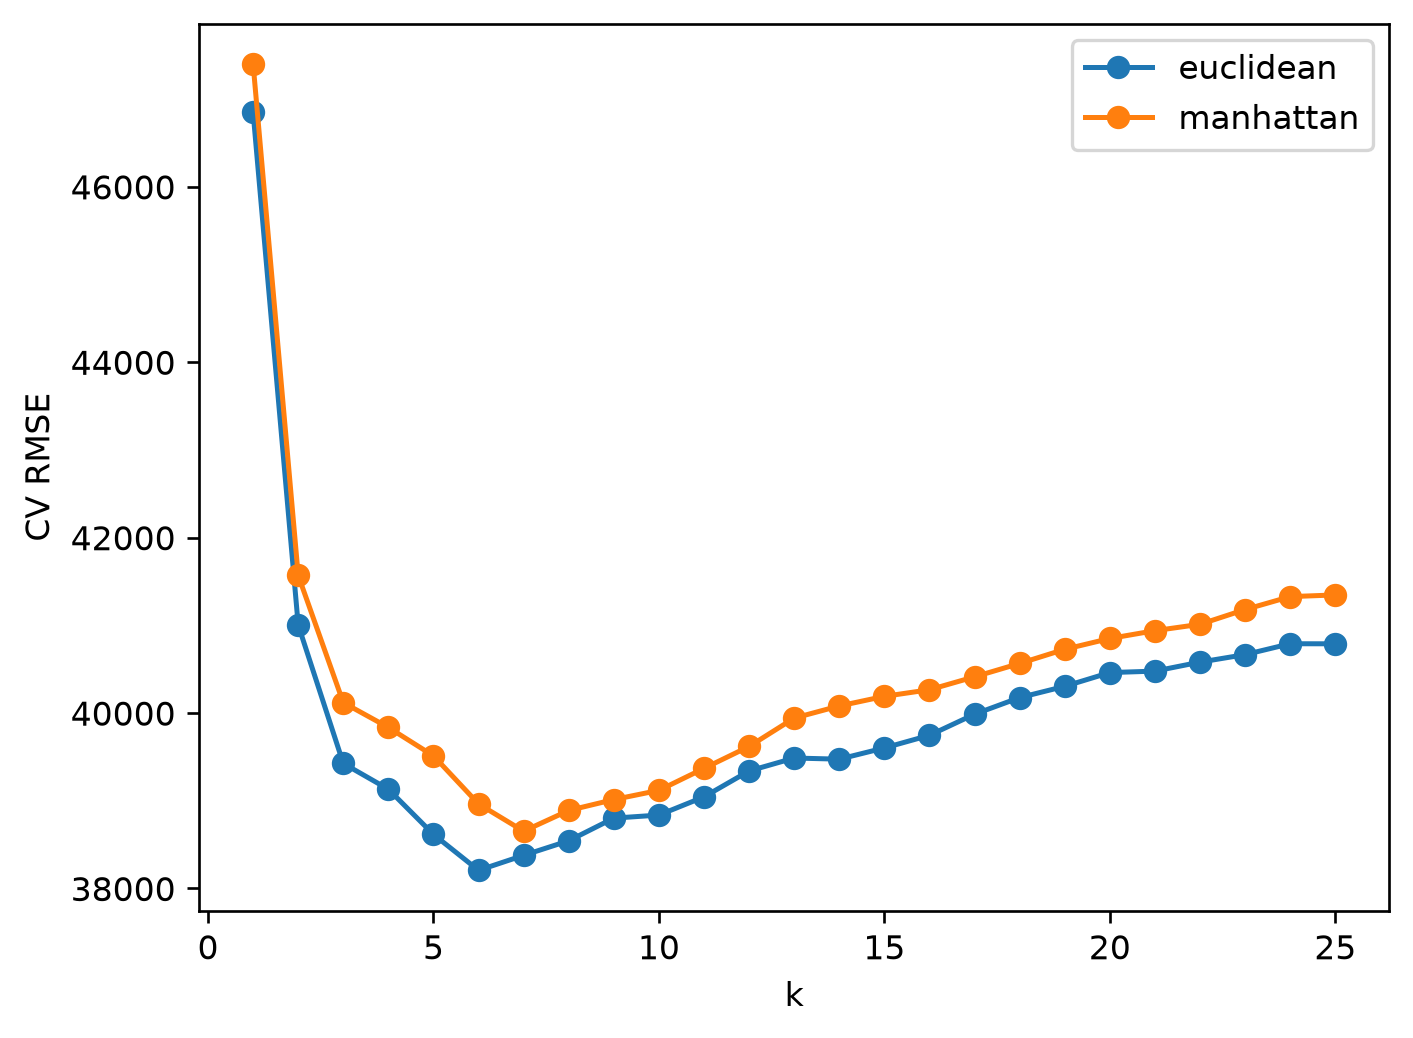

In [20]:
# YOUR CODE HERE. ADD CELLS AS NEEDED
pipe = Pipeline([("prep", preprocessing(numeric, categorical)),
                 ("knn", KNeighborsRegressor())])

param_grid = {"knn__n_neighbors": range(1, 26),
              "knn__metric": ["euclidean", "manhattan"]}

grid = GridSearchCV(pipe, param_grid, cv=folds, scoring="neg_root_mean_squared_error")
grid.fit(df_ames[columns], y)
print(grid.best_params_, round(-grid.best_score_))

res = pd.DataFrame(grid.cv_results_)
res["rmse"] = -res["mean_test_score"]
for m, g in res.groupby("param_knn__metric"):
    plt.plot(g["param_knn__n_neighbors"], g["rmse"], marker="o", label=m)
plt.xlabel("k"); plt.ylabel("CV RMSE"); plt.legend(); plt.show()

4\. Combine elements of the previous parts and fit what you think will be the best $k$-nearest neighbors model. Specify which features you are using, the value of $k$, and the distance metric. Estimate the test error. (In 2-3 you used the specified set of features. Now you can combine elements of 2-3 with the features you chose in part 1, or other sets of features, as well as investigating other parameter choices.)

Note: Look at the [`KNeighborsRegressor` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html) for a full list of parameters. You might consider tuning `n_neighbors`, `metric` (or `p`), and/or `weights`. You could also try other elements like scaling too.

In [21]:
# YOUR CODE HERE. ADD CELLS AS NEEDED
numeric4 = ["Gr Liv Area", "Overall Qual", "Year Built", "Total Bsmt SF", "Garage Cars"]
categorical4 = ["Neighborhood"]
cols4 = numeric4 + categorical4

pipe4 = Pipeline([("prep", preprocessing(numeric4, categorical4)),
                  ("knn", KNeighborsRegressor())])
grid4 = GridSearchCV(pipe4,
    {"knn__n_neighbors": range(1, 26),
     "knn__metric": ["euclidean", "manhattan"],
     "knn__weights": ["uniform", "distance"]},
    cv=folds, scoring="neg_root_mean_squared_error")
grid4.fit(df_ames[cols4], y)
print(grid4.best_params_, round(-grid4.best_score_))

{'knn__metric': 'euclidean', 'knn__n_neighbors': 10, 'knn__weights': 'distance'} 28924


5\. Now fit a linear regression model using the same features that you used in the previous part. Estimate the test error. How does the test error for linear regression compare to the kNN model?

Its larger.


In [22]:
# YOUR CODE HERE. ADD CELLS AS NEEDED
lin = Pipeline([("prep", preprocessing(numeric4, categorical4)),
                ("lr", LinearRegression())])
print(round(cv_rmse(lin, cols4)))

33891


## Loans Data

The loans data set represents thousands of loans made through the Lending Club platform, which is a platform that allows individuals to lend to other individuals. Of course, not all loans are created equal. Someone who is a essentially a sure bet to pay back a loan will have an easier time getting a loan with a low interest rate than someone who appears to be riskier. And for people who are very risky? They may not even get a loan offer, or they may not have accepted the loan offer due to a high interest rate. It is important to keep that last part in mind, since this dataset only represents loans actually made, i.e. do not mistake this data for loan applications!

[Some information about the data set is here](https://openintrostat.github.io/openintro/reference/loans_full_schema.html). There are also some related exercises in this [OpenIntro textbook](https://openintro-ims.netlify.app/inf-model-mlr.html).

**Our goal will be to develop a regression model for predicting `interest_rate`.**

We will have a competition to see who can come up with the model with the smallest test RMSE. Fit several models and try to find the smallest test RMSE. When you think you have a good one, share your model and its test RMSE. Then see what other people have done; can you do even better?

Note: when you are consider features to include, you might want to consider transformations of the variables.

You should use `GridSearchCV` to tune at least one parameter.

Note: you should do some exploration of the data first before you start fitting models.

In [24]:
df = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/refs/heads/main/data/loans_full_schema.csv")

df

,Unnamed: 0,emp_title,emp_length,state,homeownership,annual_income,verified_income,debt_to_income,annual_income_joint,verification_income_joint,...,sub_grade,issue_month,loan_status,initial_listing_status,disbursement_method,balance,paid_total,paid_principal,paid_interest,paid_late_fees
0,1,global config engineer,3.0,NJ,MORTGAGE,90000.0,Verified,18.01,NaN,NaN,...,C3,Mar-2018,Current,whole,Cash,27015.86,1999.33,984.14,1015.19,0.0
1,2,warehouse office clerk,10.0,HI,RENT,40000.0,Not Verified,5.04,NaN,NaN,...,C1,Feb-2018,Current,whole,Cash,4651.37,499.12,348.63,150.49,0.0
2,3,assembly,3.0,WI,RENT,40000.0,Source Verified,21.15,NaN,NaN,...,D1,Feb-2018,Current,fractional,Cash,1824.63,281.80,175.37,106.43,0.0
3,4,customer service,1.0,PA,RENT,30000.0,Not Verified,10.16,NaN,NaN,...,A3,Jan-2018,Current,whole,Cash,18853.26,3312.89,2746.74,566.15,0.0
4,5,security supervisor,10.0,CA,RENT,35000.0,Verified,57.96,57000.0,Verified,...,C3,Mar-2018,Current,whole,Cash,21430.15,2324.65,1569.85,754.80,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,owner,10.0,TX,RENT,108000.0,Source Verified,22.28,NaN,NaN,...,A4,Jan-2018,Current,whole,Cash,21586.34,2969.80,2413.66,556.14,0.0
9996,9997,director,8.0,PA,MORTGAGE,121000.0,Verified,32.38,NaN,NaN,...,D3,Feb-2018,Current,whole,Cash,9147.44,1456.31,852.56,603.75,0.0
9997,9998,toolmaker,10.0,CT,MORTGAGE,67000.0,Verified,45.26,107000.0,Source Verified,...,E2,Feb-2018,Current,fractional,Cash,27617.65,4620.80,2382.35,2238.45,0.0
9998,9999,manager,1.0,WI,MORTGAGE,80000.0,Source Verified,11.99,NaN,NaN,...,A1,Feb-2018,Current,whole,Cash,21518.12,2873.31,2481.88,391.43,0.0


(10000, 56)
count    10000.000000
mean        12.427524
std          5.001105
min          5.310000
25%          9.430000
50%         11.980000
75%         15.050000
max         30.940000
Name: interest_rate, dtype: float64
verification_income_joint           0.8545
annual_income_joint                 0.8505
debt_to_income_joint                0.8505
months_since_90d_late               0.7715
months_since_last_delinq            0.5658
months_since_last_credit_inquiry    0.1271
emp_title                           0.0833
emp_length                          0.0817
num_accounts_120d_past_due          0.0318
debt_to_income                      0.0024
dtype: float64


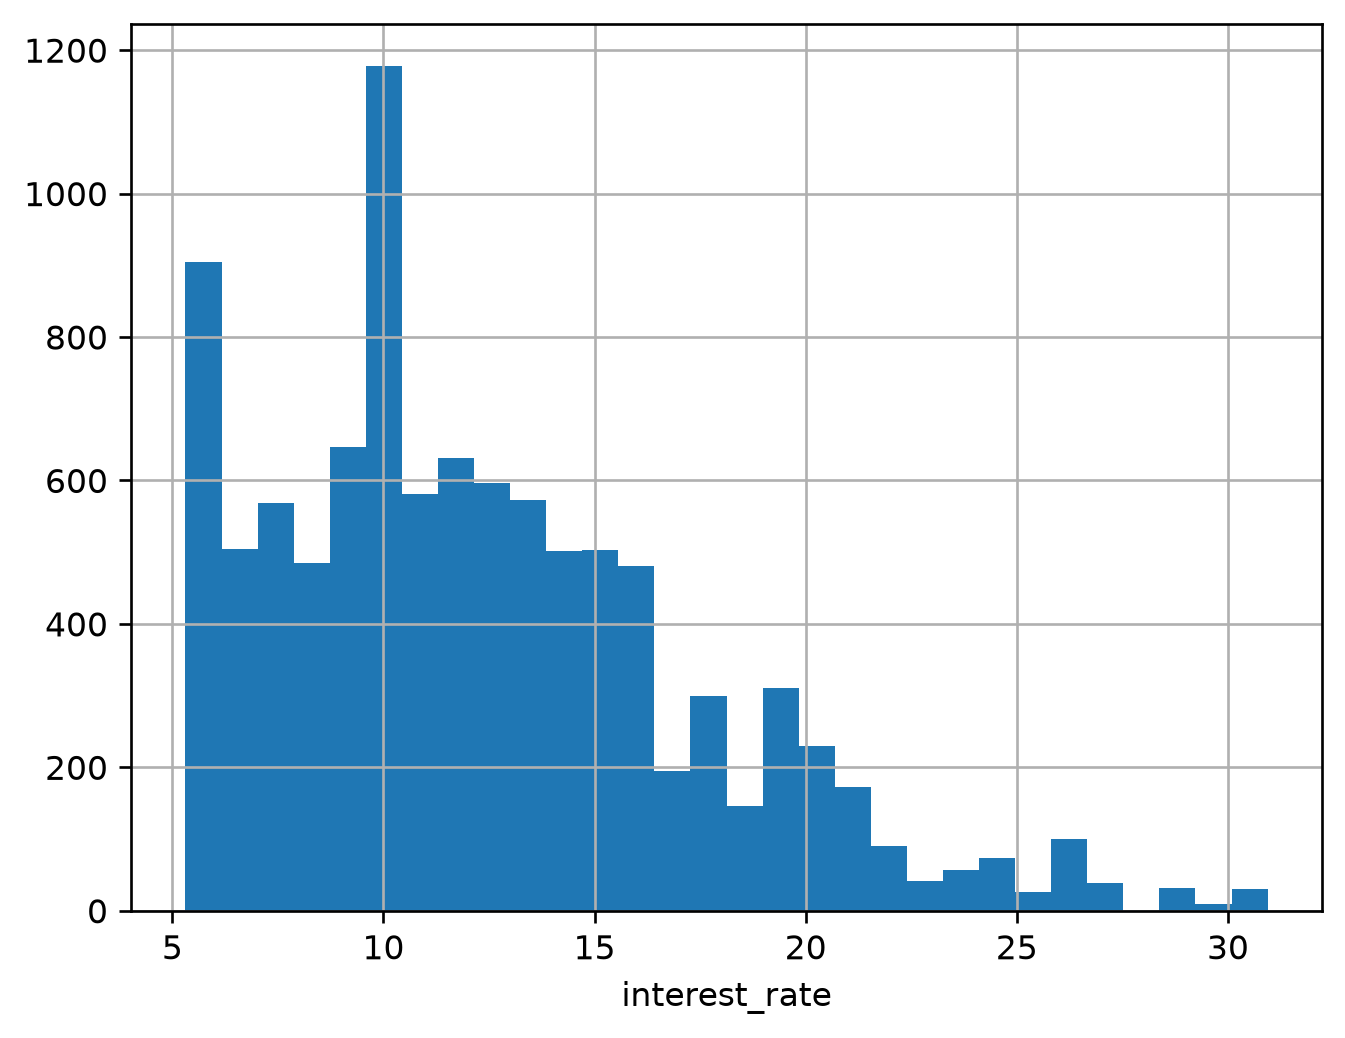

term
36    11.244927
60    15.147888
Name: interest_rate, dtype: float64
homeownership
MORTGAGE    12.058868
OWN         12.313991
RENT        12.924959
Name: interest_rate, dtype: float64


,interest_rate,annual_income,debt_to_income,loan_amount
interest_rate,1.000000,-0.099584,0.141653,0.064527
annual_income,-0.099584,1.000000,-0.180445,0.324665
debt_to_income,0.141653,-0.180445,1.000000,0.056329
loan_amount,0.064527,0.324665,0.056329,1.000000


In [25]:
# YOUR CODE HERE. ADD CELLS AS NEEDED
print(df.shape)
print(df["interest_rate"].describe())
print(df.isna().mean().sort_values(ascending=False).head(10))   # which columns have missing values

df["interest_rate"].hist(bins=30); plt.xlabel("interest_rate"); plt.show()
print(df.groupby("term")["interest_rate"].mean())
print(df.groupby("homeownership")["interest_rate"].mean())
df[["interest_rate", "annual_income", "debt_to_income", "loan_amount"]].corr()

In [27]:
from sklearn.model_selection import train_test_split
# income, credit limit and loan amount are right-skewed, so use logs
for c in ["annual_income", "total_credit_limit", "total_credit_utilized", "loan_amount"]:
    df["log_" + c] = np.log1p(df[c])

numeric = ["log_loan_amount", "term", "log_annual_income", "debt_to_income", "delinq_2y",
           "inquiries_last_12m", "total_credit_lines", "open_credit_lines",
           "log_total_credit_limit", "log_total_credit_utilized",
           "num_collections_last_12m", "public_record_bankrupt", "accounts_opened_24m"]
categorical = ["homeownership", "verified_income", "loan_purpose", "application_type"]
numeric = [c for c in numeric if c in df.columns]        # drops any name I got wrong
categorical = [c for c in categorical if c in df.columns]
cols = numeric + categorical

X = df[cols]; y = df["interest_rate"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=5544)

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split

# dense preprocessing so HistGradientBoosting accepts it
prep = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical)])

ridge = GridSearchCV(Pipeline([("prep", prep), ("m", Ridge())]),
                     {"m__alpha": [0.01, 0.1, 1, 10, 100]},
                     cv=5, scoring="neg_root_mean_squared_error")

hgb = GridSearchCV(Pipeline([("prep", prep), ("m", HistGradientBoostingRegressor(random_state=5544))]),
                   {"m__learning_rate": [0.03, 0.1], "m__max_depth": [3, 5, None],
                    "m__max_iter": [200, 500]},
                   cv=5, scoring="neg_root_mean_squared_error")

for name, g in [("ridge", ridge), ("hist gradient boosting", hgb)]:
    g.fit(X_train, y_train)
    pred = g.predict(X_test)
    print(name, g.best_params_,
          "CV RMSE:", round(-g.best_score_, 3),
          "held-out test RMSE:", round(np.sqrt(np.mean((y_test - pred) ** 2)), 3))

ridge {'m__alpha': 100} CV RMSE: 4.199 held-out test RMSE: 4.152
